# BÀI KIỂM TRA 1 – KHÁM PHÁ DỮ LIỆU (EDA) & TIỀN XỬ LÝ
**Đề tài:** Phân tích giỏ hàng và phát hiện các sản phẩm thường được mua kèm

**Nhóm 23 (CNTT K22H – ICTU):** Trần Văn Thực (`DTC235200734`), Nguyễn Đức An Bình (`DTC235200066`)

**GVHD:** ThS. Nguyễn Tuấn Anh

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'bai1' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data_pipeline import (
    load_raw_baskets,
    prepare_dataset,
    compute_item_frequencies,
    compute_cooccurrence_matrix,
)

plt.rcParams['figure.dpi'] = 120
raw_baskets = load_raw_baskets(ROOT / 'data' / 'groceries.csv')
print(f'Tổng số giao dịch gốc: {len(raw_baskets):,}')
print('5 giỏ hàng mẫu:', raw_baskets[:5])

Tổng số giao dịch gốc: 9,835
5 giỏ hàng mẫu: [['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups'], ['tropical fruit', 'yogurt', 'coffee'], ['whole milk'], ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads'], ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']]


## 1. Khảo sát thống kê mô tả & Phân bố sản phẩm (EDA)

In [2]:
bundle_raw = prepare_dataset(raw_baskets, min_basket_size=1, test_size=0.20, random_state=42)
print('Thống kê dữ liệu gốc:')
for k in ['n_raw_transactions', 'n_unique_items', 'avg_basket_size', 'std_basket_size', 'median_basket_size', 'max_basket_size', 'sparsity_pct', 'single_item_count']:
    print(f'  {k}: {bundle_raw.stats[k]:.2f}' if isinstance(bundle_raw.stats[k], float) else f'  {k}: {bundle_raw.stats[k]}')

freq_raw = compute_item_frequencies(bundle_raw.clean_baskets)
freq_raw.head(15)

Thống kê dữ liệu gốc:
  n_raw_transactions: 9835
  n_unique_items: 169
  avg_basket_size: 4.41
  std_basket_size: 3.59
  median_basket_size: 3.00
  max_basket_size: 32
  sparsity_pct: 97.39
  single_item_count: 0


,item,count,support_pct
0,whole milk,2513,25.551601
1,other vegetables,1903,19.349263
2,rolls/buns,1809,18.393493
3,soda,1715,17.437722
4,yogurt,1372,13.950178
5,bottled water,1087,11.052364
6,root vegetables,1072,10.899847
7,tropical fruit,1032,10.493137
8,shopping bags,969,9.852567
9,sausage,924,9.395018


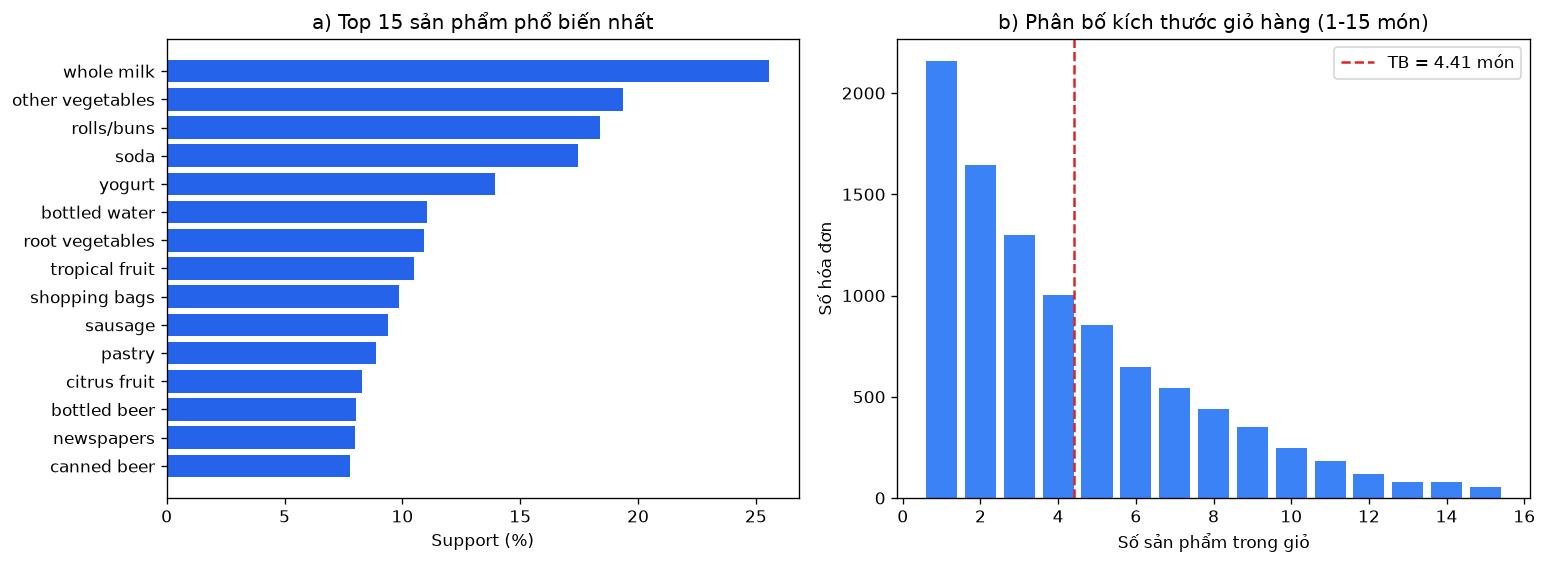

In [3]:
top15 = freq_raw.head(15).iloc[::-1]
sizes = np.array([len(b) for b in bundle_raw.clean_baskets])
counts = pd.Series(sizes[sizes <= 15]).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].barh(top15['item'], top15['support_pct'], color='#2563EB')
axes[0].set_title('a) Top 15 sản phẩm phổ biến nhất')
axes[0].set_xlabel('Support (%)')

axes[1].bar(counts.index, counts.values, color='#3B82F6')
axes[1].axvline(np.mean(sizes), color='#DC2626', linestyle='--', label=f'TB = {np.mean(sizes):.2f} món')
axes[1].set_title('b) Phân bố kích thước giỏ hàng (1-15 món)')
axes[1].set_xlabel('Số sản phẩm trong giỏ')
axes[1].set_ylabel('Số hóa đơn')
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Phân tích quan hệ đồng xuất hiện (Top 8 nhóm sản phẩm chính)

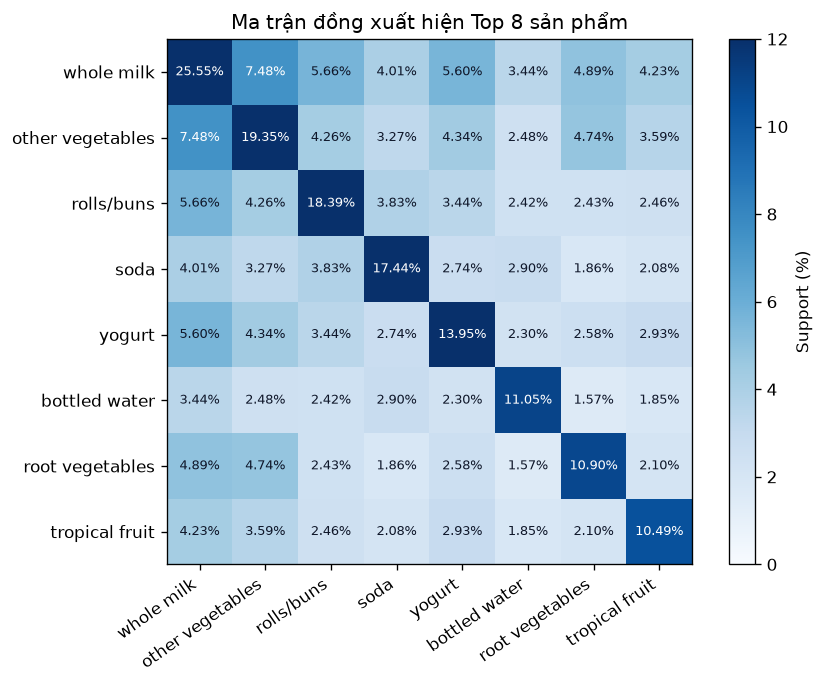

In [4]:
cooc = compute_cooccurrence_matrix(bundle_raw.clean_baskets, top_n=8)
fig, ax = plt.subplots(figsize=(7.5, 5.8))
im = ax.imshow(cooc.values, cmap='Blues', vmin=0, vmax=12)
ax.set_xticks(range(len(cooc.columns)))
ax.set_yticks(range(len(cooc.columns)))
ax.set_xticklabels(cooc.columns, rotation=35, ha='right')
ax.set_yticklabels(cooc.columns)
for i in range(len(cooc)):
    for j in range(len(cooc)):
        ax.text(j, i, f'{cooc.values[i, j]:.2f}%', ha='center', va='center', fontsize=8,
                color='white' if cooc.values[i, j] > 7 else '#0F172A')
fig.colorbar(im, ax=ax, label='Support (%)')
ax.set_title('Ma trận đồng xuất hiện Top 8 sản phẩm')
plt.tight_layout()
plt.show()

## 3. Tiền xử lý làm sạch, lọc giỏ < 2 món và chia Hold-out 80/20 chống rò rỉ

In [5]:
bundle = prepare_dataset(raw_baskets, min_basket_size=2, test_size=0.20, random_state=42)
summary_df = pd.DataFrame([
    {'Giai đoạn': 'Dữ liệu gốc', 'Số giỏ': bundle_raw.stats['n_raw_transactions'], 'Độ dài TB': round(bundle_raw.stats['avg_basket_size'], 2), 'Độ dày ma trận (%)': round(100 - bundle_raw.stats['sparsity_pct'], 2)},
    {'Giai đoạn': 'Sau lọc >= 2 món (Train 80%)', 'Số giỏ': bundle.stats['n_train'], 'Độ dài TB': round(float(np.mean([len(b) for b in bundle.train_baskets])), 2), 'Độ dày ma trận (%)': round(bundle.stats['train_density_pct'], 2)},
    {'Giai đoạn': 'Sau lọc >= 2 món (Test 20%)', 'Số giỏ': bundle.stats['n_test'], 'Độ dài TB': round(float(np.mean([len(b) for b in bundle.test_baskets])), 2), 'Độ dày ma trận (%)': round(bundle.stats['test_density_pct'], 2)},
])
summary_df

,Giai đoạn,Số giỏ,Độ dài TB,Độ dày ma trận (%)
0,Dữ liệu gốc,9835,4.41,2.61
1,Sau lọc >= 2 món (Train 80%),6140,5.41,3.22
2,Sau lọc >= 2 món (Test 20%),1536,5.22,3.11
